# Panel of series: several series in the same experiment

With a panel, the candidates are compared on **all** series at once:

1. Each series has its own **sealed test**, its validation origins and its MASE scale.
2. The **ranking** uses the best configuration of each structure **in each series** and averages the ranks across series (convention v1, ADR-0004).
3. The **incremental selection** pools the `series:fold` units of all series: median gain and win rate are computed over the whole set.
4. **Finalization** refits each series with the configuration chosen for it and returns a `PanelForecaster`.

A hybrid that helps a lot in one series and hurts in another may be rejected on the whole. This is intentional: the decision holds for the panel.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Build the panel

Three equivalent input forms: a dict `{id: pd.Series}`, a `PanelFrame` or a long table with the columns named explicitly.

In [2]:
from autohybts import AutoHybridExperiment, PanelFrame
from autohybts.datasets import get_data

series = {
    "store_a": get_data("synthetic_daily", n=400, seed=1),
    "store_b": get_data("synthetic_daily", n=400, seed=2, phi=0.2),
    "store_c": get_data("white_noise_daily", n=400, seed=3),
}
panel = PanelFrame.from_dict(series)
long = panel.to_long()
long.head()

,series_id,timestamp,value
0,store_a,2024-01-01,50.000000
1,store_a,2024-01-02,53.197113
2,store_a,2024-01-03,53.890354
3,store_a,2024-01-04,50.722393
4,store_a,2024-01-05,49.255224


## 2. Experiment

The same call as for a single series. For the long table, give `series_col`, `date_col` and `target`.

In [3]:
exp = AutoHybridExperiment(
    fh=14,
    session_id=42,
    fold=3,
    base_models=["naive", "seasonal_naive", "linear", "knn"],
    correctors=["linear"],
    residual_windows=[7],
).fit(long, series_col="series_id", date_col="timestamp", target="value")
exp.splits.head(8)

layer train_start     origin first_target last_target  \
series_id fold_id                                                            
store_a    search-0  search  2024-01-01 2024-10-28   2024-10-29  2024-11-11   
          search-1  search  2024-01-01 2024-11-11   2024-11-12  2024-11-25   
          search-2  search  2024-01-01 2024-11-25   2024-11-26  2024-12-09   
          select-0  select  2024-01-01 2024-12-09   2024-12-10  2024-12-23   
          select-1  select  2024-01-01 2024-12-23   2024-12-24  2025-01-06   
          select-2  select  2024-01-01 2025-01-06   2025-01-07  2025-01-20   
store_b    search-0  search  2024-01-01 2024-10-28   2024-10-29  2024-11-11   
          search-1  search  2024-01-01 2024-11-11   2024-11-12  2024-11-25   

                    n_train  horizon  
series_id fold_id                     
store_a    search-0      302       14  
          search-1      316       14  
          search-2      330       14  
          select-0      344       14  
          select-1      358       14  
          select-2      372       14  
store_b    search-0      302       14  
          search-1      316       14

In [4]:
exp.data_profile()

,store_a,store_b,store_c
série,store_a,store_b,store_c
início,2024-01-01 00:00:00,2024-01-01 00:00:00,2024-01-01 00:00:00
fim,2025-01-20 00:00:00,2025-01-20 00:00:00,2025-01-20 00:00:00
observações,386,386,386
frequência,D,D,D
faltantes,0,0,0
datas duplicadas,0,0,0
média,55.484794,55.726255,50.031984
desvio-padrão,4.0998,3.953511,1.012719
mínimo,45.566595,46.758314,46.941619


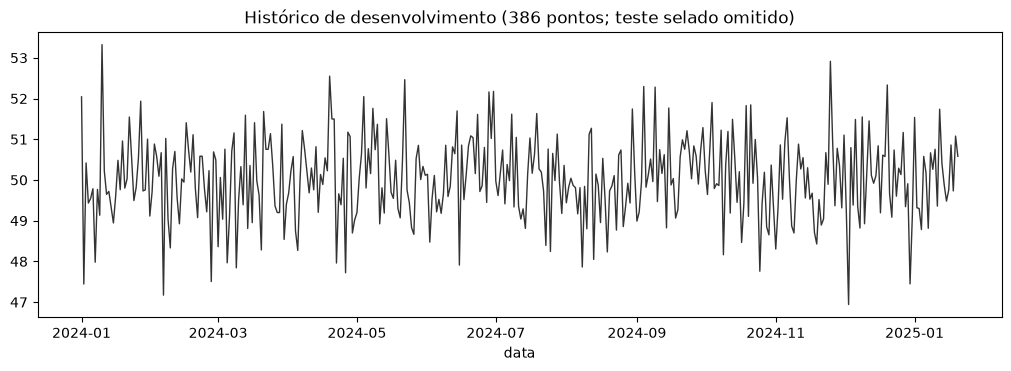

In [5]:
exp.plot_data("series", series_id="store_c")

## 3. Search, ranking across series and selection

In [6]:
result = exp.compare_models()
result.leaderboard.head(10)

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4,linear,linear(lags=7),linear,standalone,linear,NaN,NaN,NaN,NaN,1.0,...,1.187120,1.400000,0.020918,1.0,9,0,0,4.669229,0.085078,True
c4821c0a39e39a26ca17be31d8298f1ebcaed90d98e0a1fd3722f7c6ed592f9b,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,2.0,...,1.197439,1.402873,0.021120,1.0,9,0,0,2.202428,0.154874,False
b678627c69f0bc5eb419617a2119103a8a5340ac96c0551898c62a1d76dc0179,linear-linear,"linear(lags=7) + linear [w=7, alpha=1.0, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,1.0,3.0,...,1.221169,1.431294,0.021547,1.0,9,0,0,2.096703,0.119330,False
70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d09d35dac0019c7ef37,knn,knn(lags=7),kernel,standalone,knn,NaN,NaN,NaN,NaN,4.0,...,1.270992,1.540000,0.022512,1.0,9,0,0,0.134471,0.303800,False
773d3b8c8d625571d4d4b4f4aa234d9f88b9b7fc0ceb3101c126e49e100378fc,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_1step,7.0,0.5,5.0,...,1.313242,1.537258,0.023246,1.0,9,0,0,0.942562,0.056509,False
507265ea41efe47e82119ba51bc162c1cd983e9fd72f0a1b25e7ca1c8d95b229,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_1step,7.0,1.0,6.0,...,1.339927,1.581616,0.023777,1.0,9,0,0,0.906525,0.069950,False
d90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238,seasonal_naive,seasonal_naive(season_length=7),statistical,standalone,seasonal_naive,NaN,NaN,NaN,NaN,7.0,...,1.342596,1.570915,0.023741,1.0,9,0,0,0.000790,0.001136,False
2948929df89de24864d7dc328f6eaad73372295f0ac9c1a0b90ee60e1d5a5bf3,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_multistep,7.0,0.5,8.0,...,1.520219,1.761318,0.026350,1.0,9,0,0,1.553121,0.149621,False
bbd8aa955229e78f79ee95ec40b350010922f578702fd6a464ea2ea729023f34,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_multistep,7.0,0.5,9.0,...,1.591184,1.894029,0.028089,1.0,9,0,0,0.849400,0.063294,False


Decision history: `median_gain` and `win_rate` come from the units of **all** series (`n_units`). The variability of the correction is computed per series (median of the units of each series) and the value of the decision is the median across series.

In [7]:
result.decisions

,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate,variability_status,variability_value,p_value,challenger_coverage,challenger_label,champion_before_id,challenger_id
0,statistical,linear,seasonal_naive,False,"(median_gain_below_threshold, win_rate_below_t...",-0.318080,0.111111,not_applicable,NaN,None,1.0,seasonal_naive(season_length=7),e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...,d90528888825a4459816afbcf249ff909747924f0a2bba...
1,kernel,linear,knn,False,"(median_gain_below_threshold, win_rate_below_t...",-0.299249,0.111111,not_applicable,NaN,None,1.0,knn(lags=7),e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...,70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d...
2,residual,linear,linear-linear,False,"(median_gain_below_threshold,)",0.013144,0.777778,passed,0.316343,None,1.0,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...,c4821c0a39e39a26ca17be31d8298f1ebcaed90d98e0a1...


In [8]:
for decision in result.selection.decisions:
    if decision.variability_by_series:
        print(decision.family, "→", decision.variability_value)
        print({sid: round(value, 4) for sid, value in decision.variability_by_series.items()})

residual → 0.3163430777874731
{'store_a': 0.4355, 'store_b': 0.3163, 'store_c': 0.1533}


Configuration of the champion structure in each series (the best configuration per series):

In [9]:
{sid: spec.label for sid, spec in result.selection.champion_per_series.items()}

{'store_a': 'linear(lags=7)',
 'store_b': 'linear(lags=7)',
 'store_c': 'linear(lags=7)'}

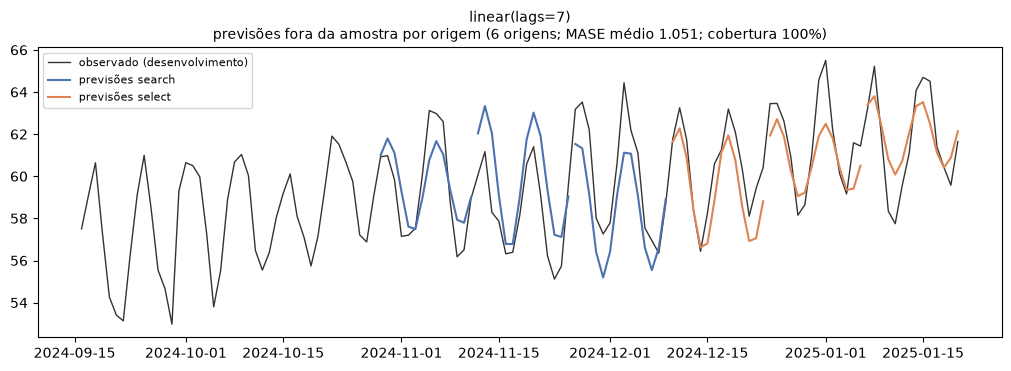

In [10]:
exp.plot_model(result.best, "cv_forecasts", series_id="store_a")

## 4. Temporal cross-validation on the panel

The folds are created per series; the comparison units are `series:fold`.

In [11]:
cv = exp.cross_validate(models=["naive", "seasonal_naive", "linear", result.best], folds=4)
cv.summary

,mean,std,median,n_valid,n_units,mean_rank
model,,,,,,
linear(lags=7) #e9e747,0.888316,0.221479,0.884719,12,12,1.166667
seasonal_naive,1.105422,0.249782,1.055381,12,12,2.000000
naive,1.656280,0.569859,1.631295,12,12,2.833333


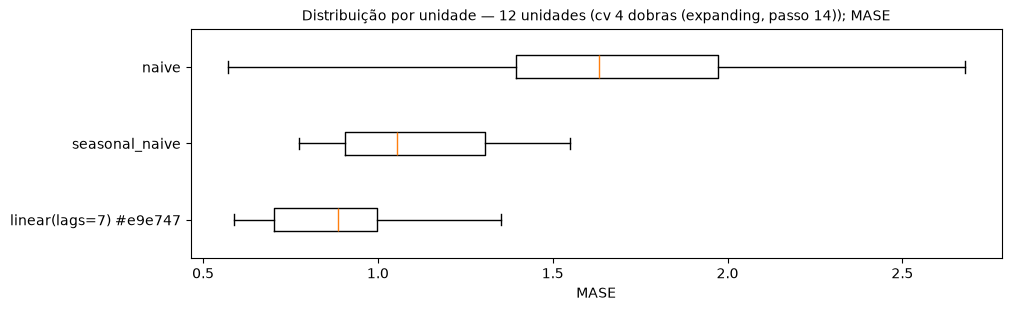

In [12]:
cv.plot("boxplot")

## 5. Finalize, forecast and evaluate on the sealed test

Each series is refitted with its own configuration up to the end of its development history. The external evaluation gives one row per series and the mean; it can be done only once per model.

In [13]:
model = exp.finalize_model(result.best)
model

PanelForecaster('linear(lags=7)', 3 séries)

In [14]:
exp.predict_model(model).predictions.groupby("series_id").head(3)

,series_id,origin,horizon,y_pred
timestamp,,,,
2025-01-21,store_a,2025-01-20,1,63.861809
2025-01-22,store_a,2025-01-20,2,64.882571
2025-01-23,store_a,2025-01-20,3,64.128668
2025-01-21,store_b,2025-01-20,1,63.489836
2025-01-22,store_b,2025-01-20,2,64.030801
2025-01-23,store_b,2025-01-20,3,62.515433
2025-01-21,store_c,2025-01-20,1,50.023368
2025-01-22,store_c,2025-01-20,2,50.018118
2025-01-23,store_c,2025-01-20,3,49.992272


In [15]:
exp.evaluate_external(model).metrics

MASE       MAE      RMSE     sMAPE
model          series_id                                        
linear(lags=7) store_a     0.904739  1.093430  1.449512  0.017839
               store_b     0.947833  1.122680  1.328718  0.018160
               store_c     0.623558  0.690681  0.873767  0.013812
               média      0.825377  0.968931  1.217332  0.016603

## 6. Save and load

In [16]:
import tempfile

from autohybts import load_model, save_model

with tempfile.TemporaryDirectory() as folder:
    path = save_model(model, folder)
    loaded = load_model(path, trusted=True)
loaded.predict(3)

,series_id,origin,horizon,y_pred
timestamp,,,,
2025-01-21,store_a,2025-01-20,1,63.861809
2025-01-22,store_a,2025-01-20,2,64.882571
2025-01-23,store_a,2025-01-20,3,64.128668
2025-01-21,store_b,2025-01-20,1,63.489836
2025-01-22,store_b,2025-01-20,2,64.030801
2025-01-23,store_b,2025-01-20,3,62.515433
2025-01-21,store_c,2025-01-20,1,50.023368
2025-01-22,store_c,2025-01-20,2,50.018118
2025-01-23,store_c,2025-01-20,3,49.992272
